# Задание 3. Регрессия количества аренд велосипедов

Вариант 4 — чётный. Ноутбук запускается независимо от остальных: выполните ячейки сверху вниз. Данные включены в служебную ячейку; если рядом находится одноимённый CSV, используется он. Приведённые числовые выводы относятся к встроенным исходным данным и SEED = 42.

Источник: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), H. Fanaee-T, DOI 10.24432/C5W894, CC BY 4.0. Цель — предсказать `cnt`, число аренд за сутки.

In [1]:
# При необходимости раскомментируйте и выполните один раз:
# %pip install numpy pandas matplotlib "scikit-learn>=1.2" threadpoolctl

In [2]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

from sklearn.neural_network import MLPClassifier, MLPRegressor

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

SEED = 42
MAX_EPOCHS = 350
PATIENCE = 35

np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 20)
from sklearn.metrics import classification_report, f1_score
from sklearn.dummy import DummyClassifier, DummyRegressor

### Параметры эксперимента

- `SEED = 42` фиксирует разбиение данных и начальные веса.
- `MAX_EPOCHS = 350` задаёт предельное число проходов по обучению.
- `PATIENCE = 35` — количество эпох без улучшения валидационной ошибки.

Обучение останавливается раньше максимума, если валидационная ошибка перестаёт уменьшаться. Тестовая выборка не участвует в выборе весов и архитектуры.

In [3]:
import base64, gzip, io
from pathlib import Path

# Используем локальный CSV, а при его отсутствии — встроенную копию.
DATA_NAME = 'day.csv'
DATA_B64 = '...'
def load_data():
    if Path(DATA_NAME).is_file():
        return pd.read_csv(DATA_NAME, sep=',')
    return pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(DATA_B64))), sep=',')

## Загрузка и подготовка данных

Размер таблицы: (731, 16)
Количество пропусков: 0
Повторяющиеся даты: 0
Обучение: (511, 35)
Валидация: (110, 35)
Тест: (110, 35)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000,211.166,1.000,183.500,366.000,548.500,731.000
season,731.0,2.497,1.111,1.000,2.000,3.000,3.000,4.000
yr,731.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000
mnth,731.0,6.520,3.452,1.000,4.000,7.000,10.000,12.000
holiday,731.0,0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,731.0,2.997,2.005,0.000,1.000,3.000,5.000,6.000
workingday,731.0,0.684,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,731.0,1.395,0.545,1.000,1.000,1.000,2.000,3.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841


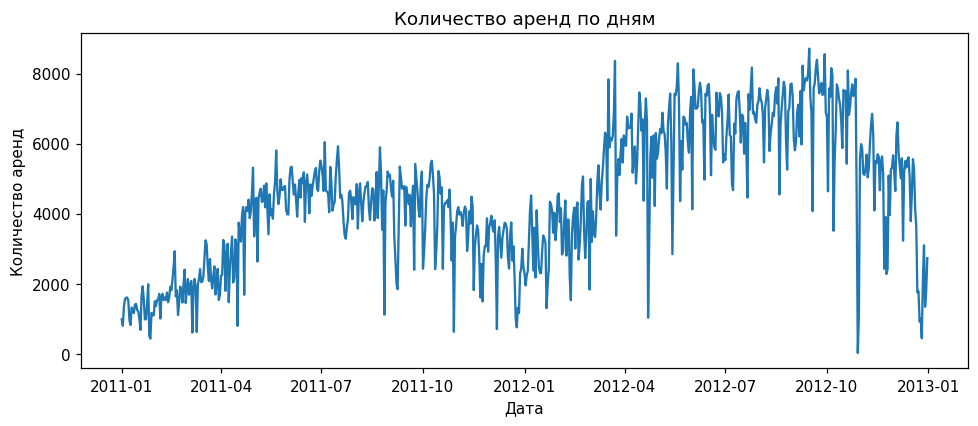

In [4]:
bike = load_data()

print("Размер таблицы:", bike.shape)
print("Количество пропусков:", bike.isna().sum().sum())
print("Повторяющиеся даты:", bike["dteday"].duplicated().sum())

display(bike.head())
display(bike.describe().T.round(3))

assert not bike["dteday"].duplicated().any()
assert (bike["casual"] + bike["registered"] == bike["cnt"]).all()

dates = pd.to_datetime(bike["dteday"])

X = bike.drop(columns=["cnt", "casual", "registered", "instant", "dteday"]).copy()

y = bike["cnt"].astype(float)

# Представляем положение дня в годовом цикле.
days_in_year = np.where(dates.dt.is_leap_year, 366, 365)

X["day_sin"] = np.sin( 2 * np.pi * (dates.dt.dayofyear - 1) / days_in_year)

X["day_cos"] = np.cos( 2 * np.pi * (dates.dt.dayofyear - 1) / days_in_year)

numeric_columns = [
    "temp", "atemp", "hum", "windspeed",
    "day_sin", "day_cos"
]

categorical_columns = [
    "season", "mnth", "weekday", "weathersit"
]

binary_columns = [
    "yr", "holiday", "workingday"
]

Xr_train, Xr_rest, yr_train, yr_rest = train_test_split( X, y, test_size=0.30, random_state=SEED)

Xr_val, Xr_test, yr_val, yr_test = train_test_split(Xr_rest, yr_rest, test_size=0.50, random_state=SEED)

preprocessor_r = ColumnTransformer([
    (
        "numeric",
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler() ),
        numeric_columns
    ),
    (
        "categorical",
        make_pipeline(SimpleImputer(strategy="most_frequent"),  OneHotEncoder( handle_unknown="ignore", sparse_output=False )),
        categorical_columns
    ),
    (
        "binary",
        SimpleImputer(strategy="most_frequent"),
        binary_columns
    )
])

Xr_train = preprocessor_r.fit_transform(Xr_train)
Xr_val = preprocessor_r.transform(Xr_val)
Xr_test = preprocessor_r.transform(Xr_test)

yr_train = yr_train.to_numpy()
yr_val = yr_val.to_numpy()
yr_test = yr_test.to_numpy()

# Масштабируем цель только по обучающим значениям.
target_scaler = StandardScaler()

yr_train_scaled = target_scaler.fit_transform(yr_train.reshape(-1, 1)).ravel()

yr_val_scaled = target_scaler.transform(yr_val.reshape(-1, 1)).ravel()

print("Обучение:", Xr_train.shape)
print("Валидация:", Xr_val.shape)
print("Тест:", Xr_test.shape)

plt.plot(dates, bike["cnt"])
plt.title("Количество аренд по дням")
plt.xlabel("Дата")
plt.ylabel("Количество аренд")
plt.tight_layout()
plt.show()

### Описание данных и выполненной обработки

1. В таблице **731 день и 16 столбцов** за 2011–2012 годы. Пропуски и повторные даты не обнаружены. Цель `cnt` изменяется от **22 до 8714**, среднее число аренд — **4504,35**, медиана — **4548**.
2. Погодные признаки `temp`, `atemp`, `hum`, `windspeed` описывают температуру, ощущаемую температуру, влажность и ветер. `season`, `mnth`, `weekday`, `weathersit` задают сезон, месяц, день недели и погоду. `yr`, `holiday`, `workingday` описывают год, праздничный и рабочий день.
3. Удалены `instant` и исходная строка даты. Из даты рассчитаны синус и косинус положения дня в году. Они учитывают цикличность: конец декабря близок к началу января.
4. `casual` и `registered` исключены, поскольку их сумма равна `cnt`. Оставление этих столбцов передало бы модели готовый ответ.
5. Случайное разбиение даёт **511 / 110 / 110** записей. После One-Hot Encoding получается **35 входов**. Кодировщик и масштабирование обучены только на train. Цель тоже стандартизирована; все итоговые ошибки возвращаются к исходному масштабу.

На графике видны колебания спроса и годовая сезонность. Случайное разделение оценивает дни того же периода с известной погодой; оно не проверяет прогнозирование будущих лет.

In [5]:
display(bike.dtypes.to_frame("Тип"))
q1, q3 = bike["cnt"].quantile([.25,.75])
iqr = q3-q1
print("Кандидаты в выбросы cnt:", ((bike["cnt"] < q1-1.5*iqr) | (bike["cnt"] > q3+1.5*iqr)).sum())

Кандидаты в выбросы cnt: 0


,Тип
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64


Крайние значения спроса не удаляются автоматически: они могут отражать реальные дни с необычной погодой или календарными условиями.

## Архитектуры и обучение

In [6]:
configs = [
    {
        "name": "16_relu_adam",
        "layers": (16,),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_relu_adam",
        "layers": (32,),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "64_32_relu_adam",
        "layers": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_16_tanh_adam",
        "layers": (32, 16),
        "activation": "tanh",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_16_relu_sgd",
        "layers": (32, 16),
        "activation": "relu",
        "solver": "sgd",
        "lr": 0.01,
        "alpha": 0.001
    },
    {
        "name": "64_32_16_relu_adam",
        "layers": (64, 32, 16),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.01
    }
]

display(pd.DataFrame(configs))

,name,layers,activation,solver,lr,alpha
0,16_relu_adam,"(16,)",relu,adam,0.001,0.001
1,32_relu_adam,"(32,)",relu,adam,0.001,0.001
2,64_32_relu_adam,"(64, 32)",relu,adam,0.001,0.001
3,32_16_tanh_adam,"(32, 16)",tanh,adam,0.001,0.001
4,32_16_relu_sgd,"(32, 16)",relu,sgd,0.010,0.001
5,64_32_16_relu_adam,"(64, 32, 16)",relu,adam,0.001,0.010


- Создаются шесть конфигураций полносвязных нейронных сетей. Они отличаются количеством скрытых слоёв, числом нейронов, функциями активации ReLU и tanh, а также оптимизаторами Adam и SGD.

- Для каждой конфигурации задаются скорость обучения **lr** и коэффициент **L2-регуляризации alpha** - такая регуляризация ограничивает рост весов и помогает снижать переобучение (добавляет штраф за большие значения весов и помогает ограничивать сложность модели.)

In [7]:
def train_model(config, X_train, y_train, X_val, y_val, task):
    if task == "classification":
        model_class = MLPClassifier
    else:
        model_class = MLPRegressor

    model = model_class(
        hidden_layer_sizes=config["layers"],
        activation=config["activation"],
        solver=config["solver"],
        learning_rate_init=config["lr"],
        learning_rate="constant",
        alpha=config["alpha"],
        batch_size=64,
        momentum=0.9,
        shuffle=True,
        early_stopping=False,
        random_state=SEED,
        max_iter=1
    )

    history = []
    best_loss = np.inf
    best_model = None
    best_epoch = 0
    waiting = 0

    with threadpool_limits(limits=1):
        for epoch in range(1, MAX_EPOCHS + 1):
            if task == "classification":
                model.partial_fit( X_train, y_train, classes=classes )

                train_loss = log_loss(y_train, model.predict_proba(X_train),labels=classes)

                val_loss = log_loss(y_val,model.predict_proba(X_val), labels=classes )

            else:
                model.partial_fit(X_train, y_train)

                train_loss = mean_squared_error(y_train, model.predict(X_train))

                val_loss = mean_squared_error(y_val, model.predict(X_val))

            history.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            if val_loss < best_loss - 1e-6:
                best_loss = val_loss
                best_model = copy.deepcopy(model)
                best_epoch = epoch
                waiting = 0
            else:
                waiting += 1

            if waiting >= PATIENCE:
                break

    parameters = (sum(weights.size for weights in best_model.coefs_) + sum(bias.size for bias in best_model.intercepts_))

    return {
        "model": best_model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "parameters": parameters
    }


def plot_training(result, title, ylabel):
    history = result["history"]

    plt.figure()

    plt.plot(history["epoch"], history["train_loss"], label="Обучение")

    plt.plot(history["epoch"], history["val_loss"], label="Валидация")

    plt.axvline( result["best_epoch"], color="gray", linestyle="--",  label="Сохранённая эпоха")

    plt.title(title)
    plt.xlabel("Эпоха")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Функция `train_model` выполняет по одной эпохе через `partial_fit`. Для регрессии используется линейный выход и квадратичная ошибка; графики показывают MSE стандартизированной цели. Размер пакета — 64. После 35 эпох без улучшения валидационной MSE обучение прекращается и восстанавливается лучшая копия сети. Ограничение потоков не меняет принцип обучения.

Функция `predict_rental` возвращает прогноз из стандартизированного масштаба в количество аренд. Предсказания не округляются и не обрезаются, чтобы оценка соответствовала исходному выходу модели.

16_relu_adam — обучение завершено
32_relu_adam — обучение завершено
64_32_relu_adam — обучение завершено
32_16_tanh_adam — обучение завершено
32_16_relu_sgd — обучение завершено
64_32_16_relu_adam — обучение завершено
Выбран регрессор: 32_16_tanh_adam


,model,parameters,best_epoch,epochs_run,val_MSE,val_MAE,val_R2
0,16_relu_adam,593,148,183,432788.0107,464.4272,0.8959
1,32_relu_adam,1185,113,148,361060.8594,437.4257,0.9131
2,64_32_relu_adam,4417,44,79,329465.5395,422.5787,0.9207
3,32_16_tanh_adam,1697,108,143,300456.8360,386.8078,0.9277
4,32_16_relu_sgd,1697,68,103,375458.0851,431.3481,0.9097
5,64_32_16_relu_adam,4929,30,65,295713.4057,394.9731,0.9289


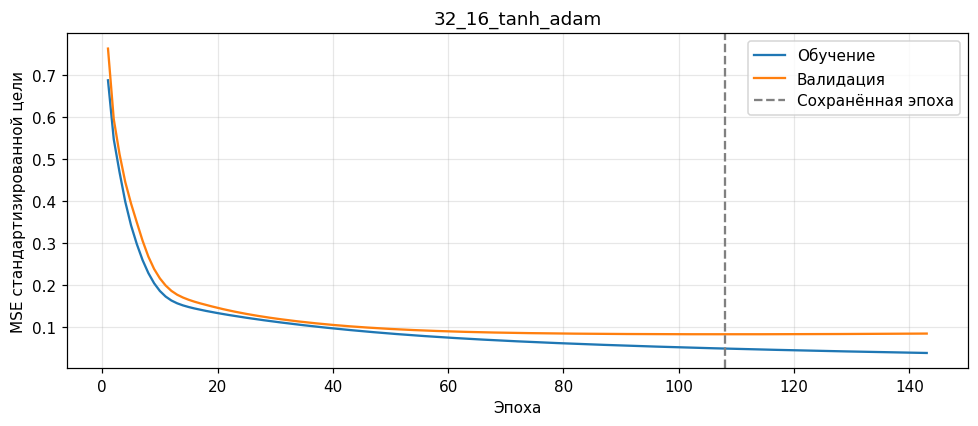

In [8]:
def predict_rental(model, X):
    prediction_scaled = model.predict(X)

    return target_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    ).ravel()


regression_runs = {}
validation_rows = []

for config in configs:
    result = train_model(
        config,
        Xr_train,
        yr_train_scaled,
        Xr_val,
        yr_val_scaled,
        task="regression"
    )

    name = config["name"]
    regression_runs[name] = result

    prediction = predict_rental(
        result["model"],
        Xr_val
    )

    validation_rows.append({
        "model": name,
        "parameters": result["parameters"],
        "best_epoch": result["best_epoch"],
        "epochs_run": len(result["history"]),
        "val_MSE": mean_squared_error(yr_val, prediction),
        "val_MAE": mean_absolute_error(yr_val, prediction),
        "val_R2": r2_score(yr_val, prediction)
    })

    print(name, "— обучение завершено")

validation_r = pd.DataFrame(validation_rows)

display(validation_r.round(4))

min_mse = validation_r["val_MSE"].min()

candidates = validation_r[
    validation_r["val_MSE"] <= min_mse * 1.02
]

best_r_name = candidates.sort_values(
    ["parameters", "val_MSE"]
).iloc[0]["model"]

best_r = regression_runs[best_r_name]["model"]

print("Выбран регрессор:", best_r_name)

plot_training(
    regression_runs[best_r_name],
    best_r_name,
    "MSE стандартизированной цели"
)

### Выбор модели по валидации

Обучаются шесть конфигураций. Минимальная валидационная MSE равна **295713,4057** у `64_32_16_relu_adam`. В пределах 2% от минимума находится `32_16_tanh_adam` с MSE **300456,8360**. Её ошибка выше примерно на 1,6%, зато параметров **1697 вместо 4929**. Поэтому выбрана более компактная сеть `32_16_tanh_adam`.

Сохранены веса 108-й эпохи. Всего выполнено 143 эпохи: после лучшего результата прошло 35 эпох без достаточного улучшения. Выбор сделан до просмотра тестовых метрик.

## Проверка регрессоров на тесте

In [9]:
regression_rows = []

for name, result in regression_runs.items():
    prediction = predict_rental(
        result["model"],
        Xr_test
    )

    regression_rows.append({
        "model": name,
        "MSE": mean_squared_error(yr_test, prediction),
        "MAE": mean_absolute_error(yr_test, prediction),
        "R2": r2_score(yr_test, prediction)
    })

baseline_prediction = np.full(
    len(yr_test),
    yr_train.mean()
)

regression_rows.append({
    "model": "Среднее обучающей выборки",
    "MSE": mean_squared_error(yr_test, baseline_prediction),
    "MAE": mean_absolute_error(yr_test, baseline_prediction),
    "R2": r2_score(yr_test, baseline_prediction)
})

regression_metrics = pd.DataFrame(
    regression_rows
).set_index("model")

display(regression_metrics.round(4))

,MSE,MAE,R2
model,,,
16_relu_adam,4.550567e+05,497.8232,0.8802
32_relu_adam,4.532304e+05,508.0430,0.8807
64_32_relu_adam,5.056228e+05,513.3417,0.8669
32_16_tanh_adam,4.287754e+05,473.0087,0.8871
32_16_relu_sgd,3.766052e+05,446.2605,0.9009
64_32_16_relu_adam,4.021040e+05,460.4639,0.8942
Среднее обучающей выборки,3.821083e+06,1632.5334,-0.0057


### Сравнение результатов

| Модель | MSE | MAE | R² |
|---|---:|---:|---:|
| 16_relu_adam | 455056,7 | 497,82 | 0,8802 |
| 32_relu_adam | 453230,4 | 508,04 | 0,8807 |
| 64_32_relu_adam | 505622,8 | 513,34 | 0,8669 |
| 32_16_tanh_adam | 428775,4 | 473,01 | 0,8871 |
| 32_16_relu_sgd | 376605,2 | 446,26 | 0,9009 |
| 64_32_16_relu_adam | 402104,0 | 460,46 | 0,8942 |
| Среднее train | 3821083 | 1632,53 | −0,0057 |

**MSE** измеряется в арендах² и сильнее реагирует на большие ошибки. **MAE** измеряется в арендах и позволяет оценить среднее абсолютное отклонение. **R²** сравнивает квадрат ошибки с разбросом тестовой цели; отрицательное значение допустимо.

На тесте наиболее высокое качество получила `32_16_relu_sgd`, но она хуже выбранной модели на валидации. Поэтому итоговый выбор не меняется. Увеличение ширины или глубины не гарантирует улучшения: `64_32_relu_adam` имеет наибольшую тестовую MSE среди сетей. Это результаты конфигураций в целом, а не изолированное влияние одного параметра.

Все сети заметно лучше постоянного прогноза. Для выбранной модели MAE составляет **473 аренды**, против **1633** у базового прогноза. Предсказание среднего train эквивалентно `DummyRegressor(strategy="mean")`; ниже это проверяется явно.

Базовый прогноз совпадает с DummyRegressor.


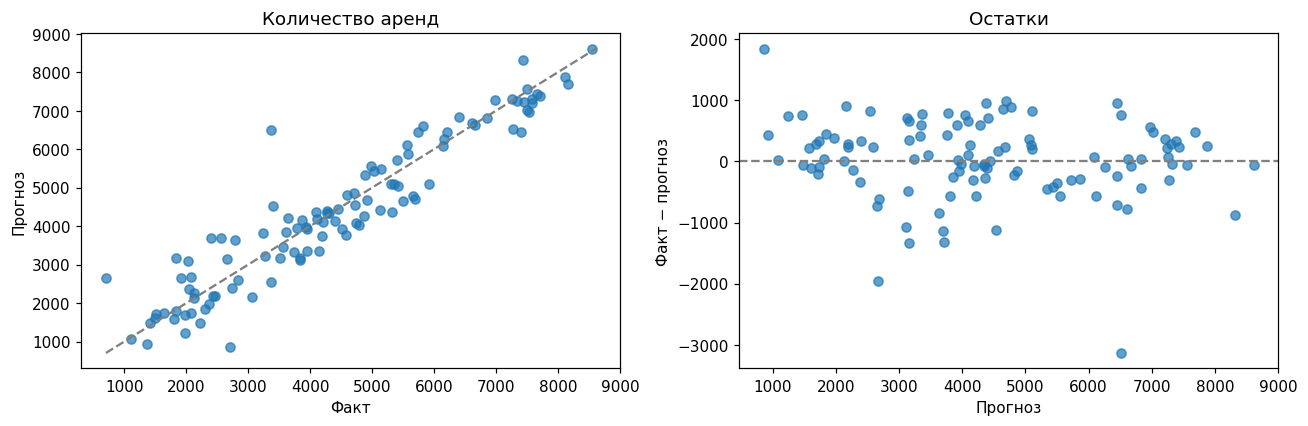

In [10]:
dummy_r = DummyRegressor(strategy='mean').fit(Xr_train, yr_train)
assert np.allclose(dummy_r.predict(Xr_test), baseline_prediction)
print('Базовый прогноз совпадает с DummyRegressor.')
pred = predict_rental(best_r, Xr_test)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(yr_test,pred,alpha=.7)
a,b = min(yr_test.min(),pred.min()),max(yr_test.max(),pred.max())
axes[0].plot([a,b],[a,b],'--',color='gray')
axes[0].set(xlabel='Факт',ylabel='Прогноз',title='Количество аренд')
axes[1].scatter(pred,yr_test-pred,alpha=.7)
axes[1].axhline(0,color='gray',linestyle='--')
axes[1].set(xlabel='Прогноз',ylabel='Факт − прогноз',title='Остатки')
plt.tight_layout();plt.show()

Точки около диагонали соответствуют точным прогнозам. На графике остатков положительное значение означает недооценку спроса, отрицательное — завышение. Крупные остатки показывают дни, для которых модель ошибается сильнее обычного.

## Итог и переобучение

In [11]:
print("РЕГРЕССОР")

print("Выбранная модель:", best_r_name)

display(
    regression_metrics.loc[[best_r_name]].round(4)
)

train_r2 = r2_score(
    yr_train,
    predict_rental(best_r, Xr_train)
)

val_r2 = r2_score(
    yr_val,
    predict_rental(best_r, Xr_val)
)

print(f"R² на обучении: {train_r2:.3f}")
print(f"R² на валидации: {val_r2:.3f}")
print(f"Разрыв: {train_r2 - val_r2:.3f}")

РЕГРЕССОР
Выбранная модель: 32_16_tanh_adam
R² на обучении: 0.952
R² на валидации: 0.928
Разрыв: 0.024


,MSE,MAE,R2
model,,,
32_16_tanh_adam,428775.4036,473.0087,0.8871


У выбранной сети R² на обучении равен примерно **0,952**, на валидации — **0,928**. Разрыв **0,024** невелик по сравнению с классификатором Fetal Health. На тесте R² = **0,8871**. Снижение тестового качества относительно валидации показывает, что выводы зависят от конкретного разбиения.

Ориентир R² ≥ 0,80 выполнен. Модель объясняет значительную часть вариации суточного спроса, но средняя абсолютная ошибка остаётся около 473 аренд. Один эксперимент не доказывает отсутствие переобучения. Для проверки будущего периода требуется хронологическое разделение и прогнозы погоды, доступные на момент предсказания.